# SolarGuard LSS: calibrating a parametric solar insurance product with 25 years of NASA satellite data

**The question.** In our university group project we designed *SolarGuard LSS*, an insurance product that pays Malaysian large-scale solar (LSS) farms when cloudy weather cuts their revenue. The payout depends on how many *low-sunlight days* a month has. When we priced it, the chance of each payout tier was a **placeholder guess**.

**This notebook replaces the guesses with real data.** It uses 25 years (2001–2025) of daily satellite sunlight readings for a site in Kedah, northern Malaysia, to answer:

1. How often would each payout tier really have triggered?
2. What premium does that imply, compared with our original estimate?
3. Is it safe to treat each day as independent? (Spoiler: no, and it matters.)

In [1]:
# Setup. In Google Colab, this pulls the project code from GitHub first.
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")
if not os.path.isdir("solarguard"):                   # running in Google Colab: fetch the code from GitHub
    REPO = "https://github.com/DylanAmbrose892/solarguard-calibration.git"
    os.system(f"git clone -q {REPO}")
    os.chdir("solarguard-calibration")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from solarguard import core as sg

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. The product, as designed in the group project

An example 50 MWac solar plant earns about **RM16.15M a year** (50 MW × 1,900 MWh per MW × RM0.17 per kWh). We insure one month of that revenue, **RM1.35M**, and pay a share of it depending on how many low-sunlight days the month had:

| Low-sunlight days in the month | Payout (share of monthly sum insured) |
|---|---|
| 5 to 7 | 20% (RM269k) |
| 8 to 14 | 45% (RM606k) |
| 15 or more | 100% (RM1.35M) |

First, a check that the code reproduces the numbers in the original deck.

In [2]:
print(f"Annual revenue:         RM{sg.ANNUAL_REVENUE:,.0f}")
print(f"Monthly sum insured:    RM{sg.MONTHLY_SUM_INSURED:,.0f}")
print(f"Annual aggregate limit: RM{sg.ANNUAL_AGGREGATE_LIMIT:,.0f}")

deck_ep = sg.expected_annual_payout(sg.DECK_TIER_PROBS)
deck_premium = sg.premium(deck_ep)
print(f"\nDeck (placeholder odds) -> expected payout RM{deck_ep:,.0f}/yr, "
      f"premium RM{deck_premium:,.0f} ({deck_premium / sg.ANNUAL_REVENUE:.1%} of revenue)")

Annual revenue:         RM16,150,000
Monthly sum insured:    RM1,345,833
Annual aggregate limit: RM4,037,500

Deck (placeholder odds) -> expected payout RM456,238/yr, premium RM593,109 (3.7% of revenue)


## 2. The data: daily sunlight from NASA POWER

[NASA POWER](https://power.larc.nasa.gov/) provides free, satellite-derived weather data for any point on Earth. We use **ALLSKY_SFC_SW_DWN**: the total solar energy reaching the ground each day, clouds included, in kWh per m² per day. This is the variable a parametric trigger would be built on: independent, consistent, and impossible for the plant operator to manipulate.

Site: **5.81°N, 100.47°E** (Kedah), 1 January 2001 to 31 December 2025.

In [3]:
LAT, LON = 5.81, 100.47
ghi = sg.fetch_nasa_power(LAT, LON, "20010101", "20251231",
                          cache_path="data/nasa_power_kedah_2001_2025.csv")

print(f"{len(ghi):,} days, {ghi.isna().sum()} missing")
ghi.describe().to_frame().T

9,131 days, 0 missing


,count,mean,std,min,25%,50%,75%,max
ghi_kwh_m2_day,"9,131.00",5.05,1.03,0.86,4.44,5.20,5.77,7.61


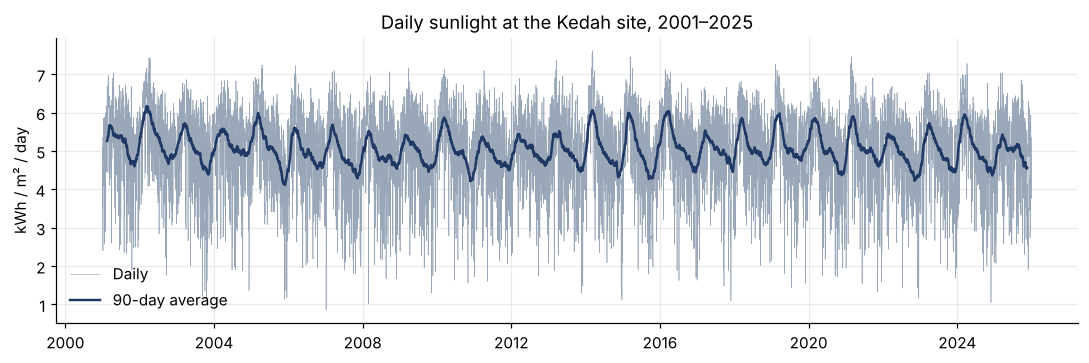

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(ghi.index, ghi, lw=0.4, color="#9aa7b8", label="Daily")
ax.plot(ghi.rolling(90, center=True).mean(), lw=1.6, color="#1f3864", label="90-day average")
ax.set_ylabel("kWh / m² / day")
ax.set_title("Daily sunlight at the Kedah site, 2001–2025")
ax.legend(loc="lower left", frameon=False)
fig.tight_layout(); fig.savefig("figures/01_daily_sunlight.png", dpi=150)
plt.show()

## 3. Defining a "low-sunlight day"

The deck said the threshold should be *site-calibrated*. A simple, explainable rule: **a day is "low" if it gets less than 60% of the site's long-run average sunlight.** On such a day a solar farm produces well under its normal output.

Section 7 tests how sensitive the price is to this 60% choice.

In [5]:
threshold = sg.low_day_threshold(ghi, share_of_mean=0.60)
p_low = (ghi < threshold).mean()
print(f"Long-run average: {ghi.mean():.2f} kWh/m²/day")
print(f"Low-day threshold (60%): {threshold:.2f} kWh/m²/day")
print(f"Share of all days that are 'low': {p_low:.1%}  (about {p_low * 30:.1f} days a month)")

Long-run average: 5.05 kWh/m²/day
Low-day threshold (60%): 3.03 kWh/m²/day
Share of all days that are 'low': 4.8%  (about 1.4 days a month)


## 4. Replaying 300 months of history

For every month since 2001, count the low days and work out what SolarGuard would have paid.

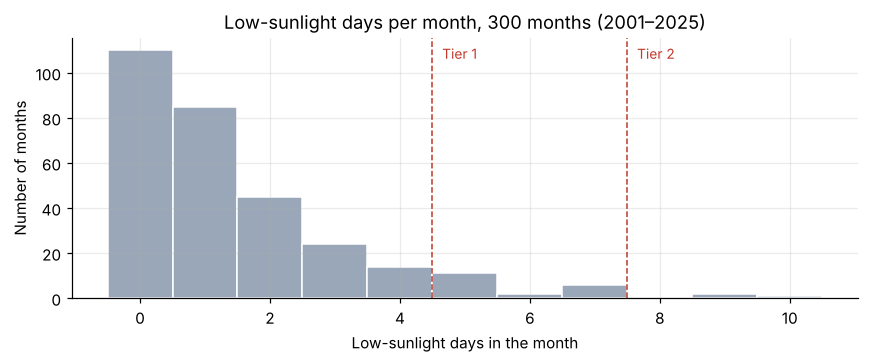

tier
No payout             278
Tier 1 (5-7 days)      19
Tier 2 (8-14 days)      3
Name: count, dtype: int64

In [6]:
counts = sg.monthly_low_days(ghi, threshold)
history = sg.payout_history(counts)

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(0, counts.max() + 2) - 0.5
ax.hist(counts, bins=bins, color="#9aa7b8", edgecolor="white")
for x, label in [(4.5, "Tier 1"), (7.5, "Tier 2")]:
    ax.axvline(x, color="#c0392b", lw=1, ls="--")
    ax.text(x + 0.15, ax.get_ylim()[1] * 0.92, label, color="#c0392b", fontsize=9)
ax.set_xlabel("Low-sunlight days in the month"); ax.set_ylabel("Number of months")
ax.set_title(f"Low-sunlight days per month, {len(counts)} months (2001–2025)")
fig.tight_layout(); fig.savefig("figures/02_low_days_histogram.png", dpi=150)
plt.show()

history["tier"].value_counts()

## 5. Real tier frequencies vs. the deck's guesses

In [7]:
real_probs = sg.tier_frequencies(counts)
comparison = pd.DataFrame({"Deck guess": sg.DECK_TIER_PROBS, "NASA data (2001–2025)": real_probs}) * 100
comparison.columns = [c + " (%)" for c in comparison.columns]

real_ep = sg.expected_annual_payout(real_probs)
real_premium = sg.premium(real_ep)

summary = pd.DataFrame({
    "Deck guess": [deck_ep, deck_premium, deck_premium / sg.ANNUAL_REVENUE * 100],
    "NASA data": [real_ep, real_premium, real_premium / sg.ANNUAL_REVENUE * 100],
}, index=["Expected payout (RM/yr)", "Premium at 1.30x loading (RM/yr)", "Premium (% of revenue)"])

display(comparison.round(1))
display(summary.style.format("{:,.1f}"))

,Deck guess (%),NASA data (2001–2025) (%)
Tier 1 (5-7 days),6.00,6.30
Tier 2 (8-14 days),2.50,1.00
Tier 3 (15+ days),0.50,0.00


,Deck guess,NASA data
Expected payout (RM/yr),"456,237.5","277,241.7"
Premium at 1.30x loading (RM/yr),"593,108.8","360,414.2"
Premium (% of revenue),3.7,2.2


## 6. Year by year: how bad can it get?

The deck capped total payouts at **RM4.04M a year** (3 × the monthly sum insured). Did any year come close?

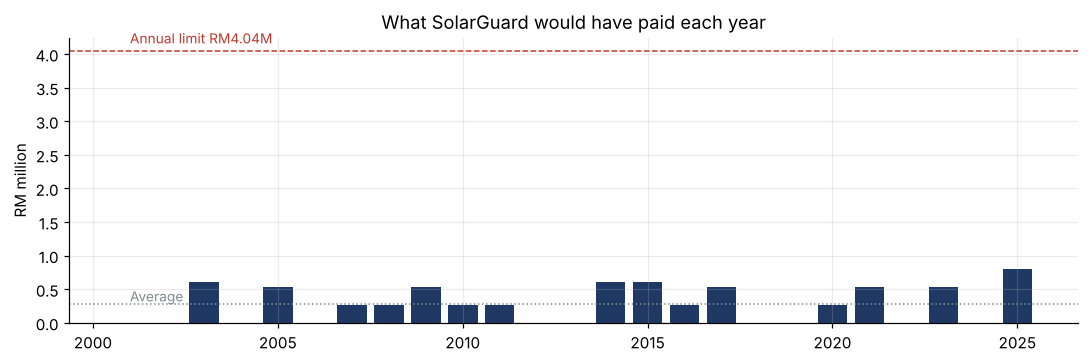

Years with no payout: 10 of 25
Worst year: 2025 (RM807,500, 20% of the limit)
Most low days in any month: 10 (Dec 2014)


In [8]:
annual = history["payout_rm"].groupby(history.index.year).sum()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(annual.index, annual / 1e6, color="#1f3864")
ax.axhline(sg.ANNUAL_AGGREGATE_LIMIT / 1e6, color="#c0392b", ls="--", lw=1)
ax.text(annual.index.min(), sg.ANNUAL_AGGREGATE_LIMIT / 1e6 * 1.03, "Annual limit RM4.04M", color="#c0392b", fontsize=9)
ax.axhline(real_ep / 1e6, color="#7f8c8d", ls=":", lw=1)
ax.text(annual.index.min(), real_ep / 1e6 * 1.15, "Average", color="#7f8c8d", fontsize=9)
ax.set_ylabel("RM million"); ax.set_title("What SolarGuard would have paid each year")
fig.tight_layout(); fig.savefig("figures/03_annual_payouts.png", dpi=150)
plt.show()

print(f"Years with no payout: {(annual == 0).sum()} of {len(annual)}")
print(f"Worst year: {annual.idxmax()} (RM{annual.max():,.0f}, {annual.max() / sg.ANNUAL_AGGREGATE_LIMIT:.0%} of the limit)")
print(f"Most low days in any month: {counts.max()} ({counts.idxmax():%b %Y})")

## 7. The key insight: cloudy days come in clusters

A tempting shortcut is to treat each day as an independent coin flip with the same small chance (about 5%) of being "low". Then the number of low days in a 30-day month follows a **binomial distribution**.

The data says that shortcut badly underestimates the risk:

In [9]:
indep = sg.binomial_tail(p_low, days=30, k=5)
actual = (counts >= 5).mean()
print(f"P(5+ low days in a month) if days were independent: {indep:.2%}")
print(f"P(5+ low days in a month) observed in the data:      {actual:.2%}  -> {actual / indep:.1f}x higher")
print(f"Correlation between 'today is low' and 'yesterday was low': {sg.lag1_autocorrelation(ghi, threshold):.2f}")

P(5+ low days in a month) if days were independent: 1.35%
P(5+ low days in a month) observed in the data:      7.33%  -> 5.4x higher
Correlation between 'today is low' and 'yesterday was low': 0.15


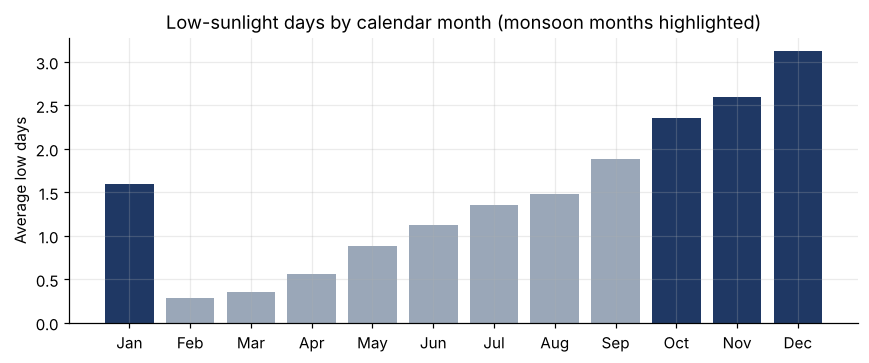

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Avg low days,1.60,0.30,0.40,0.60,0.90,1.10,1.40,1.50,1.90,2.40,2.60,3.10
% of months triggering a payout,12.00,0.00,0.00,0.00,0.00,0.00,4.00,4.00,0.00,16.00,24.00,28.00


In [10]:
by_month = counts.groupby(counts.index.month).mean()
trigger_share = (counts >= 5).groupby(counts.index.month).mean() * 100
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(names, by_month.values, color=["#1f3864" if m in (10, 11, 12, 1) else "#9aa7b8" for m in by_month.index])
ax.set_ylabel("Average low days")
ax.set_title("Low-sunlight days by calendar month (monsoon months highlighted)")
fig.tight_layout(); fig.savefig("figures/04_seasonality.png", dpi=150)
plt.show()

pd.DataFrame({"Avg low days": by_month.values, "% of months triggering a payout": trigger_share.values}, index=names).round(1).T

Two things drive the clustering:

* **Seasons.** The northeast monsoon (roughly October to January) brings weeks of cloud. Low days are far more likely then, so they pile up in the same months.
* **Weather persistence.** A cloudy day is more likely to be followed by another cloudy day.

**Why it matters for pricing:** an insurer who assumed independent days would underprice the cover by several times. The tiers must be priced from the actual distribution of monthly counts, as done here, not from a daily probability. It also tells a reinsurer *when* claims will arrive: almost all of them land in the monsoon months.

## 8. How sensitive is the price to the threshold?

The 60% rule is a judgement call. Here is what the premium would be under other choices:

In [11]:
sens = sg.threshold_sensitivity(ghi)
sens

,threshold_share_of_mean,threshold_kwh_m2_day,Tier 1 (5-7 days),Tier 2 (8-14 days),Tier 3 (15+ days),expected_payout_rm,premium_rm,premium_pct_revenue
0,0.50,2.52,0.30,0.30,0.00,34992,45489,0.28
1,0.55,2.78,2.70,0.30,0.00,110358,143466,0.89
2,0.60,3.03,6.30,1.00,0.00,277242,360414,2.23
3,0.65,3.28,9.30,2.70,0.00,495267,643847,3.99
4,0.70,3.53,14.30,5.70,0.30,928625,1207213,7.48


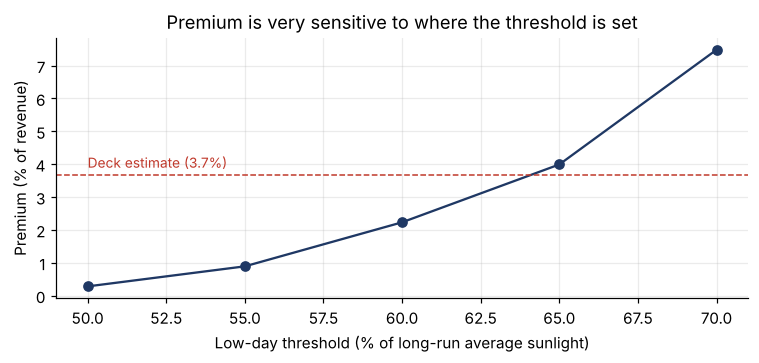

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(sens["threshold_share_of_mean"] * 100, sens["premium_pct_revenue"], marker="o", color="#1f3864")
ax.axhline(deck_premium / sg.ANNUAL_REVENUE * 100, color="#c0392b", ls="--", lw=1)
ax.text(50, deck_premium / sg.ANNUAL_REVENUE * 100 * 1.06, "Deck estimate (3.7%)", color="#c0392b", fontsize=9)
ax.set_xlabel("Low-day threshold (% of long-run average sunlight)")
ax.set_ylabel("Premium (% of revenue)")
ax.set_title("Premium is very sensitive to where the threshold is set")
fig.tight_layout(); fig.savefig("figures/05_threshold_sensitivity.png", dpi=150)
plt.show()

## 9. Limitations (what I would tell an underwriter)

* **One site.** A real product needs calibrating per plant. Kedah is one of the sunniest parts of Malaysia; a site on the east coast would face a stronger monsoon.
* **The extreme tier is unpriceable from 25 years alone.** If no month in the data reaches 15 low days, the historical Tier 3 probability is zero. That does not mean the risk is zero. A real price would add a margin for it, or model it with a fitted distribution or a longer climate record.
* **Basis risk.** The satellite reading for a grid cell is not the same as the panel output on site. Part of a plant's real loss may go unpaid, or a payout may happen when the plant did fine.
* **Climate is not fixed.** 2001–2025 may not represent the next 10 years.
* **Simplified economics.** Revenue loss on a low day is not all-or-nothing; a fuller model would link sunlight to actual MWh produced.

## 10. Conclusion

Replacing placeholder odds with 25 years of NASA data turns a classroom estimate into an evidence-based price, and surfaces the clustering of cloudy days, which is the single most important thing to get right when pricing this kind of cover.